# Tamil Abusive Comment Detection — Three-Branch Fusion Model

This Colab notebook trains and evaluates a research prototype combining:

1. **MuRIL** contextual embeddings.
2. **Character CNN** patterns for spelling variation, transliteration, and noisy social-media text.
3. **Surface-level linguistic features** such as script ratios, punctuation, repetition, digits, and emoji counts.
4. **Learned gated fusion** to combine the three representations.

It uses `train2.csv` for a stratified train/validation split and creates predictions for the unlabeled `TestV2 - testV2.csv`.

**Important research safeguards**
- The uploaded test file has no labels, so its accuracy/F1 cannot be calculated from this file.
- Validation results are model-selection results, not independent test results.
- The proposed architecture must be compared with ablations and relevant baselines before claiming novelty.
- Check the dataset licence and competition/shared-task rules before using any external dataset or publishing results.


## 1. Install dependencies and select a GPU

In Colab, choose **Runtime → Change runtime type → T4 GPU** (or another available GPU).

In [6]:
!pip -q install transformers scikit-learn pandas numpy matplotlib seaborn emoji

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## 2. Upload and load the ZIP

Run this cell and select your `datasets.zip` file. If you already extracted the files in the Colab session, you can instead set `TRAIN_PATH` and `TEST_PATH` manually.

In [7]:
from google.colab import files
uploaded = files.upload()  # select datasets.zip

import os, zipfile, glob
zip_candidates = [name for name in uploaded if name.lower().endswith(".zip")]
if not zip_candidates:
    raise ValueError("Please upload the ZIP containing train2.csv and TestV2 - testV2.csv.")

with zipfile.ZipFile(zip_candidates[0]) as zf:
    zf.extractall("/content/tamil_abuse_data")

csv_files = glob.glob("/content/tamil_abuse_data/**/*.csv", recursive=True)
print("\n".join(csv_files))

TRAIN_PATH = next((p for p in csv_files if os.path.basename(p).lower() == "train2.csv"), None)
TEST_PATH = next((p for p in csv_files if "testv2" in os.path.basename(p).lower()), None)
if TRAIN_PATH is None or TEST_PATH is None:
    raise FileNotFoundError("Could not locate train2.csv and TestV2 - testV2.csv inside the ZIP.")

import pandas as pd
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

assert {"Text", "Class"}.issubset(train_df.columns), f"Unexpected training columns: {train_df.columns.tolist()}"
assert "Text" in test_df.columns, f"Unexpected test columns: {test_df.columns.tolist()}"

train_df = train_df[["Text", "Class"]].dropna().copy()
test_df = test_df[["Text"]].dropna().copy()
train_df["Text"] = train_df["Text"].astype(str)
test_df["Text"] = test_df["Text"].astype(str)
train_df["Class"] = train_df["Class"].astype(int)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nClass counts:\n", train_df["Class"].value_counts().sort_index())
print("\nDuplicate training texts:", train_df["Text"].duplicated().sum())
print("\nSample rows:")
display(train_df.head())


Saving datasets.zip to datasets (1).zip
/content/tamil_abuse_data/datasets/train2.csv
/content/tamil_abuse_data/datasets/TestV2 - testV2.csv
Training shape: (25946, 2)
Test shape: (913, 1)

Class counts:
 Class
0    13361
1    12585
Name: count, dtype: int64

Duplicate training texts: 58

Sample rows:


,Text,Class
0,இல்லை புரோ மலேசியாவில் டிரெண்ட் ஆயிடுச்சு அதில...,0
1,ரொம்ப சந்தோஷம் இதை பாக்க ஏன்டா தமிழ் பைத்தியங்...,0
2,அவளை மாறானவராக ஆகிறாள் மருத்துவ மனையில் சேர்த்...,1
3,நீ கட்டின புடவையோட வா நான் உன்னை பாத்துக்கறேன்...,0
4,இனி அடுத்தது சூர்யா தேவி நாலு பேர் கூட்டிட்டு ...,1


## 3. Imports, reproducibility, and stratified split

The test file is not used for training or validation. The held-out validation set comes only from the labelled training file.

In [8]:
import os, re, random, math, copy, unicodedata, warnings
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, roc_auc_score
)
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type != "cuda":
    print("WARNING: GPU not detected. Training MuRIL may be slow; enable a GPU runtime in Colab.")

# Validate binary labels
labels_found = sorted(train_df["Class"].unique().tolist())
assert labels_found == [0, 1], f"Expected binary labels 0 and 1, found {labels_found}"

train_texts, val_texts, y_train, y_val = train_test_split(
    train_df["Text"].tolist(),
    train_df["Class"].to_numpy(),
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["Class"].to_numpy()
)
test_texts = test_df["Text"].tolist()

print(f"Train: {len(train_texts):,}; validation: {len(val_texts):,}; unlabeled test: {len(test_texts):,}")
print("Train label distribution:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Validation label distribution:", dict(zip(*np.unique(y_val, return_counts=True))))


Device: cuda
Train: 20,756; validation: 5,190; unlabeled test: 913
Train label distribution: {np.int64(0): np.int64(10688), np.int64(1): np.int64(10068)}
Validation label distribution: {np.int64(0): np.int64(2673), np.int64(1): np.int64(2517)}


## 4. Extract surface-level features and build a character vocabulary

Features are computed from minimally processed text. Standardization is fitted **only on the training split**. The character vocabulary is also built from training texts only.

In [9]:
# Unicode ranges used for script statistics. These count characters, not linguistic correctness.
TAMIL_RE = re.compile(r"[\\u0B80-\\u0BFF]")
LATIN_RE = re.compile(r"[A-Za-z]")
DIGIT_RE = re.compile(r"\\d")
WORD_RE = re.compile(r"\\b[A-Za-z]+\\b")
REPEATED_RE = re.compile(r"(.)\\1{2,}", flags=re.DOTALL)

try:
    import emoji
    def count_emojis(text):
        return sum(1 for ch in text if ch in emoji.EMOJI_DATA)
except Exception:
    # Fallback approximation if the emoji package is unavailable.
    def count_emojis(text):
        return sum(1 for ch in text if ord(ch) > 0x1F000)

FEATURE_NAMES = [
    "char_length", "word_count", "tamil_char_count", "latin_char_count",
    "digit_count", "tamil_ratio", "latin_ratio", "emoji_count",
    "punctuation_count", "repeated_character_runs", "english_word_count"
]

def extract_surface_features(text):
    text = str(text)
    n_chars = max(len(text), 1)
    tamil_count = len(TAMIL_RE.findall(text))
    latin_count = len(LATIN_RE.findall(text))
    digit_count = len(DIGIT_RE.findall(text))
    words = re.findall(r"\\S+", text)
    punctuation_count = sum(unicodedata.category(ch).startswith("P") for ch in text)
    repeated_runs = len(REPEATED_RE.findall(text))
    return [
        len(text),
        len(words),
        tamil_count,
        latin_count,
        digit_count,
        tamil_count / n_chars,
        latin_count / n_chars,
        count_emojis(text),
        punctuation_count,
        repeated_runs,
        len(WORD_RE.findall(text))
    ]

X_train_raw = np.asarray([extract_surface_features(t) for t in train_texts], dtype=np.float32)
X_val_raw = np.asarray([extract_surface_features(t) for t in val_texts], dtype=np.float32)
X_test_raw = np.asarray([extract_surface_features(t) for t in test_texts], dtype=np.float32)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

print("Feature count:", X_train.shape[1], FEATURE_NAMES)

MAX_CHARS = 300
PAD_ID, UNK_ID = 0, 1
char_counts = {}
for text in train_texts:
    for ch in text[:MAX_CHARS]:
        char_counts[ch] = char_counts.get(ch, 0) + 1
# Keep all observed training characters; the vocabulary should remain small for this dataset.
char_to_id = {ch: i + 2 for i, ch in enumerate(sorted(char_counts.keys()))}
CHAR_VOCAB_SIZE = len(char_to_id) + 2
print("Character vocabulary size:", CHAR_VOCAB_SIZE)

def encode_chars(text, max_chars=MAX_CHARS):
    ids = [char_to_id.get(ch, UNK_ID) for ch in str(text)[:max_chars]]
    if len(ids) < max_chars:
        ids.extend([PAD_ID] * (max_chars - len(ids)))
    return ids


Feature count: 11 ['char_length', 'word_count', 'tamil_char_count', 'latin_char_count', 'digit_count', 'tamil_ratio', 'latin_ratio', 'emoji_count', 'punctuation_count', 'repeated_character_runs', 'english_word_count']
Character vocabulary size: 206


## 5. Tokenizer and PyTorch dataset

The original comment is passed to MuRIL with minimal preprocessing. The character branch uses character IDs, while the third branch receives the standardized surface features.

In [10]:
MODEL_NAME = "google/muril-base-cased"
MAX_LENGTH = 128
BATCH_SIZE = 16  # If CUDA runs out of memory, try 8.
EPOCHS = 4
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
PATIENCE = 2

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class TamilAbuseDataset(Dataset):
    def __init__(self, texts, features, labels=None):
        self.texts = list(texts)
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = None if labels is None else torch.tensor(labels, dtype=torch.long)
        self.encodings = tokenizer(
            self.texts,
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )
        self.char_ids = torch.tensor([encode_chars(t) for t in self.texts], dtype=torch.long)

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        item = {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "char_ids": self.char_ids[idx],
            "features": self.features[idx],
        }
        if self.labels is not None:
            item["labels"] = self.labels[idx]
        return item

train_ds = TamilAbuseDataset(train_texts, X_train, y_train)
val_ds = TamilAbuseDataset(val_texts, X_val, y_val)
test_ds = TamilAbuseDataset(test_texts, X_test, labels=None)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=(DEVICE.type=="cuda"))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE*2, shuffle=False, num_workers=2, pin_memory=(DEVICE.type=="cuda"))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE*2, shuffle=False, num_workers=2, pin_memory=(DEVICE.type=="cuda"))


In [11]:
MAX_LENGTH = 96
BATCH_SIZE = 4
EPOCHS = 3
PATIENCE = 2

In [12]:
import gc
import torch
from torch.utils.data import DataLoader

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

train_ds = TamilAbuseDataset(train_texts, X_train, y_train)
val_ds = TamilAbuseDataset(val_texts, X_val, y_val)
test_ds = TamilAbuseDataset(test_texts, X_test, labels=None)

train_loader = DataLoader(
    train_ds,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_ds,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Test samples:", len(test_ds))
print("Training batches per epoch:", len(train_loader))
print("Device:", DEVICE)

Training samples: 20756
Validation samples: 5190
Test samples: 913
Training batches per epoch: 5189
Device: cuda


In [13]:
import torch
import gc

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("GPU:", torch.cuda.get_device_name(0))
    print("Total GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")
    print("Currently allocated:",
          round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GB")
    print("Currently reserved:",
          round(torch.cuda.memory_reserved(0) / 1024**3, 2), "GB")

GPU: Tesla T4
Total GPU memory: 14.56 GB
Currently allocated: 0.0 GB
Currently reserved: 0.0 GB


## 6. Three-branch gated-fusion model

The MuRIL branch encodes contextual meaning. A multi-kernel character CNN learns local character patterns at different widths. A small MLP projects surface-level features. A learned softmax gate assigns input-dependent weights to the three branches. This is the proposed model to evaluate—not a guarantee of improved performance.

In [15]:
class CharacterCNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=64, channels=96, out_dim=256, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.convs = nn.ModuleList([
            nn.Conv1d(emb_dim, channels, kernel_size=k, padding=k // 2)
            for k in (3, 4, 5)
        ])
        self.projection = nn.Sequential(
            nn.Linear(channels * len(self.convs), out_dim),
            nn.GELU(),
            nn.Dropout(0.2)
        )

    def forward(self, char_ids):
        # [batch, length, emb] -> [batch, emb, length]
        x = self.embedding(char_ids).transpose(1, 2)
        pooled = []
        for conv in self.convs:
            z = torch.relu(conv(x))
            pooled.append(torch.amax(z, dim=-1))
        return self.projection(torch.cat(pooled, dim=1))


class GatedFusionClassifier(nn.Module):
    def __init__(self, model_name, char_vocab_size, n_features, use_char=True, use_features=True):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden = self.encoder.config.hidden_size
        self.use_char = use_char
        self.use_features = use_features
        branch_count = 1 + int(use_char) + int(use_features)

        self.text_proj = nn.Sequential(
            nn.Linear(hidden, 256), nn.GELU(), nn.Dropout(0.2)
        )
        if use_char:
            self.char_encoder = CharacterCNN(char_vocab_size, out_dim=256)
            self.char_proj = nn.Identity()
        if use_features:
            self.feature_proj = nn.Sequential(
                nn.Linear(n_features, 64), nn.GELU(), nn.Dropout(0.15),
                nn.Linear(64, 256), nn.GELU()
            )

        self.gate = nn.Sequential(nn.Linear(256 * branch_count, branch_count))
        self.classifier = nn.Sequential(
            nn.Linear(256, 128), nn.GELU(), nn.Dropout(0.25),
            nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask, char_ids, features):
        enc = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        text_vec = self.text_proj(enc.last_hidden_state[:, 0, :])
        branches = [text_vec]
        if self.use_char:
            branches.append(self.char_encoder(char_ids))
        if self.use_features:
            branches.append(self.feature_proj(features))

        stacked = torch.stack(branches, dim=1)  # [batch, branches, 256]
        gate_logits = self.gate(torch.cat(branches, dim=1))
        gate_weights = torch.softmax(gate_logits, dim=1)
        fused = torch.sum(stacked * gate_weights.unsqueeze(-1), dim=1)
        logits = self.classifier(fused)
        return logits, gate_weights


model = GatedFusionClassifier(
    MODEL_NAME, CHAR_VOCAB_SIZE, X_train.shape[1],
    use_char=True, use_features=True
).to(DEVICE)

print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable parameters: 237,967,141


In [16]:

import gc
import math
import copy
import torch
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import get_linear_schedule_with_warmup

# Memory-safe training configuration
EPOCHS = 3
GRAD_ACCUM_STEPS = 4
PATIENCE = 2
use_amp = DEVICE.type == "cuda"

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Enable gradient checkpointing for MuRIL
model.encoder.gradient_checkpointing_enable()
model.encoder.config.use_cache = False

criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

updates_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM_STEPS)
total_steps = updates_per_epoch * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

scaler_amp = torch.amp.GradScaler("cuda", enabled=use_amp)

print("Training setup ready.")
print("Epochs:", EPOCHS)
print("Mini-batch size:", train_loader.batch_size)
print("Gradient accumulation:", GRAD_ACCUM_STEPS)
print("Effective batch size:", train_loader.batch_size * GRAD_ACCUM_STEPS)
print("Optimizer updates per epoch:", updates_per_epoch)


Training setup ready.
Epochs: 3
Mini-batch size: 4
Gradient accumulation: 4
Effective batch size: 16
Optimizer updates per epoch: 1298


In [17]:

def move_batch(batch):
    return {
        key: value.to(DEVICE, non_blocking=True)
        for key, value in batch.items()
    }


@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    all_probs, all_preds, all_labels = [], [], []
    total_loss, total_samples = 0.0, 0

    for batch in loader:
        batch = move_batch(batch)
        labels = batch["labels"]

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits, _ = model(
                batch["input_ids"],
                batch["attention_mask"],
                batch["char_ids"],
                batch["features"]
            )
            loss = criterion(logits, labels)

        probs = torch.softmax(logits.float(), dim=1)[:, 1]
        preds = (probs >= 0.5).long()

        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_preds)
    y_prob = np.asarray(all_probs)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "loss": total_loss / max(total_samples, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
        "labels": y_true,
        "preds": y_pred,
        "probs": y_prob
    }


best_f1 = -1.0
best_state = None
patience_left = PATIENCE
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    running_loss = 0.0
    seen = 0

    for batch_idx, batch in enumerate(train_loader):
        batch = move_batch(batch)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=use_amp
        ):
            logits, _ = model(
                batch["input_ids"],
                batch["attention_mask"],
                batch["char_ids"],
                batch["features"]
            )
            loss = criterion(logits, batch["labels"])

        scaler_amp.scale(loss / GRAD_ACCUM_STEPS).backward()

        should_update = (
            (batch_idx + 1) % GRAD_ACCUM_STEPS == 0
            or (batch_idx + 1) == len(train_loader)
        )

        if should_update:
            scaler_amp.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler_amp.step(optimizer)
            scaler_amp.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()

        batch_size = batch["labels"].size(0)
        running_loss += loss.item() * batch_size
        seen += batch_size

        if (batch_idx + 1) % 500 == 0:
            print(
                f"Epoch {epoch}/{EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(train_loader)}"
            )

    val = evaluate_model(model, val_loader)

    row = {
        "epoch": epoch,
        "train_loss": running_loss / max(seen, 1),
        "val_loss": val["loss"],
        "val_accuracy": val["accuracy"],
        "val_macro_precision": val["macro_precision"],
        "val_macro_recall": val["macro_recall"],
        "val_macro_f1": val["macro_f1"]
    }
    history.append(row)
    print(row)

    if val["macro_f1"] > best_f1:
        best_f1 = val["macro_f1"]
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }
        torch.save(best_state, "/content/best_tamil_gated_fusion.pt")
        patience_left = PATIENCE
    else:
        patience_left -= 1
        if patience_left == 0:
            print("Early stopping.")
            break

if best_state is None:
    raise RuntimeError("No model checkpoint was saved.")

model.load_state_dict(
    torch.load(
        "/content/best_tamil_gated_fusion.pt",
        map_location=DEVICE,
        weights_only=True
    )
)

training_history = pd.DataFrame(history)

print("\nBest validation macro-F1:", round(best_f1, 4))
display(training_history)


Epoch 1/3 | Batch 500/5189
Epoch 1/3 | Batch 1000/5189
Epoch 1/3 | Batch 1500/5189
Epoch 1/3 | Batch 2000/5189
Epoch 1/3 | Batch 2500/5189
Epoch 1/3 | Batch 3000/5189
Epoch 1/3 | Batch 3500/5189
Epoch 1/3 | Batch 4000/5189
Epoch 1/3 | Batch 4500/5189
Epoch 1/3 | Batch 5000/5189
{'epoch': 1, 'train_loss': 0.5820521194596217, 'val_loss': 0.44521778378642823, 'val_accuracy': 0.8169556840077071, 'val_macro_precision': 0.8221645381802525, 'val_macro_recall': 0.8149468017035226, 'val_macro_f1': 0.8154160556921264}
Epoch 2/3 | Batch 500/5189
Epoch 2/3 | Batch 1000/5189
Epoch 2/3 | Batch 1500/5189
Epoch 2/3 | Batch 2000/5189
Epoch 2/3 | Batch 2500/5189
Epoch 2/3 | Batch 3000/5189
Epoch 2/3 | Batch 3500/5189
Epoch 2/3 | Batch 4000/5189
Epoch 2/3 | Batch 4500/5189
Epoch 2/3 | Batch 5000/5189
{'epoch': 2, 'train_loss': 0.39664970746410677, 'val_loss': 0.4054702905790884, 'val_accuracy': 0.8323699421965318, 'val_macro_precision': 0.8365200336790835, 'val_macro_recall': 0.8340385267944532, 'val_mac

,epoch,train_loss,val_loss,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1
0,1,0.582052,0.445218,0.816956,0.822165,0.814947,0.815416
1,2,0.396650,0.405470,0.832370,0.836520,0.834039,0.832214
2,3,0.310570,0.389783,0.850289,0.850403,0.850704,0.850268


In [18]:
import torch
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    precision_recall_fscore_support
)

# Reload the best checkpoint saved during training
checkpoint = torch.load(
    "/content/best_tamil_gated_fusion.pt",
    map_location=DEVICE,
    weights_only=False
)

# Support either a state_dict checkpoint or a dictionary wrapper
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    model.load_state_dict(checkpoint["state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()

y_true, y_pred, y_prob = [], [], []

with torch.no_grad():
    for batch in val_loader:
        batch = move_batch(batch)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            logits, gate_weights = model(
                batch["input_ids"],
                batch["attention_mask"],
                batch["char_ids"],
                batch["features"]
            )

        probs = torch.softmax(logits.float(), dim=1)
        preds = probs.argmax(dim=1)

        y_true.extend(batch["labels"].cpu().numpy())
        y_pred.extend(preds.cpu().numpy())
        y_prob.extend(probs[:, 1].cpu().numpy())

print("Validation accuracy:", accuracy_score(y_true, y_pred))
print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    target_names=["Non-abusive", "Abusive"],
    digits=4
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred))

print("ROC-AUC:", roc_auc_score(y_true, y_prob))

Validation accuracy: 0.8502890173410405

Classification report:
              precision    recall  f1-score   support

 Non-abusive     0.8677    0.8369    0.8520      2673
     Abusive     0.8331    0.8645    0.8485      2517

    accuracy                         0.8503      5190
   macro avg     0.8504    0.8507    0.8503      5190
weighted avg     0.8509    0.8503    0.8503      5190

Confusion matrix:
[[2237  436]
 [ 341 2176]]
ROC-AUC: 0.9243848898199315


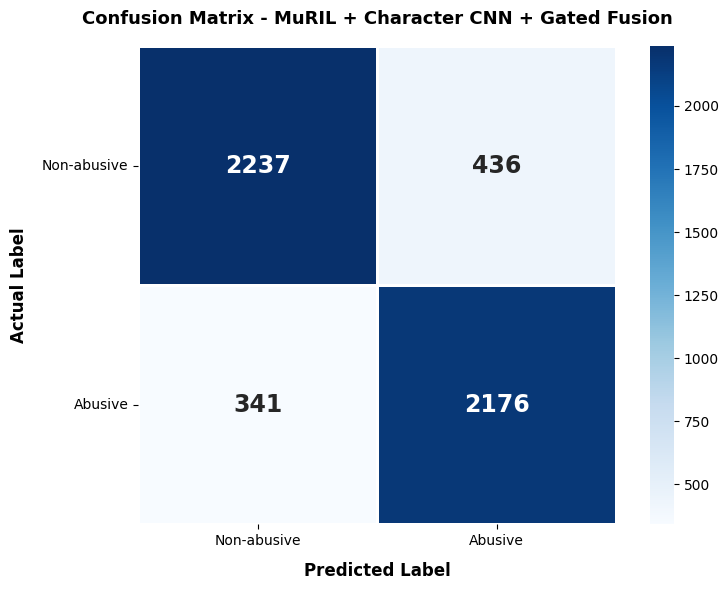

Confusion matrix:
[[2237  436]
 [ 341 2176]]
Saved as confusion_matrix_gated_fusion.png


In [20]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Actual and predicted labels from your validation evaluation
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Create a colourful confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=2,
    linecolor="white",
    square=True,
    cbar=True,
    annot_kws={"size": 17, "weight": "bold"},
    xticklabels=["Non-abusive", "Abusive"],
    yticklabels=["Non-abusive", "Abusive"]
)

plt.title(
    "Confusion Matrix - MuRIL + Character CNN + Gated Fusion",
    fontsize=13,
    fontweight="bold",
    pad=16
)
plt.xlabel("Predicted Label", fontsize=12, fontweight="bold", labelpad=10)
plt.ylabel("Actual Label", fontsize=12, fontweight="bold", labelpad=10)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10, rotation=0)

plt.tight_layout()

# Save a high-resolution image for your research paper
plt.savefig(
    "confusion_matrix_gated_fusion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix:")
print(cm)
print("Saved as confusion_matrix_gated_fusion.png")


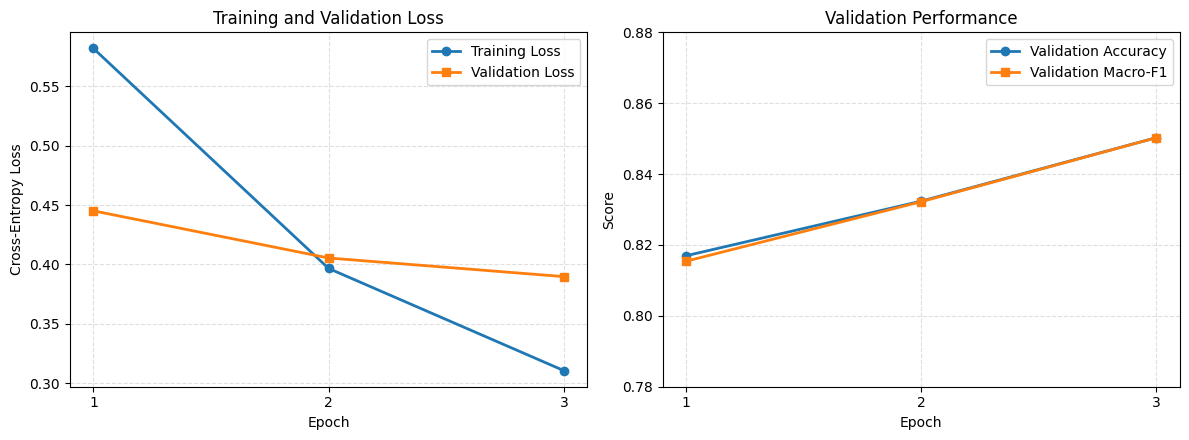

In [21]:

import matplotlib.pyplot as plt

epochs = [1, 2, 3]
train_loss = [0.582052, 0.396650, 0.310571]
val_loss = [0.445218, 0.405471, 0.389783]
val_accuracy = [0.816956, 0.832370, 0.850289]
val_macro_f1 = [0.815416, 0.832214, 0.850268]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Loss curves
axes[0].plot(epochs, train_loss, marker="o", linewidth=2,
             label="Training Loss")
axes[0].plot(epochs, val_loss, marker="s", linewidth=2,
             label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks(epochs)
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

# Validation performance
axes[1].plot(epochs, val_accuracy, marker="o", linewidth=2,
             label="Validation Accuracy")
axes[1].plot(epochs, val_macro_f1, marker="s", linewidth=2,
             label="Validation Macro-F1")
axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_xticks(epochs)
axes[1].set_ylim(0.78, 0.88)
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()


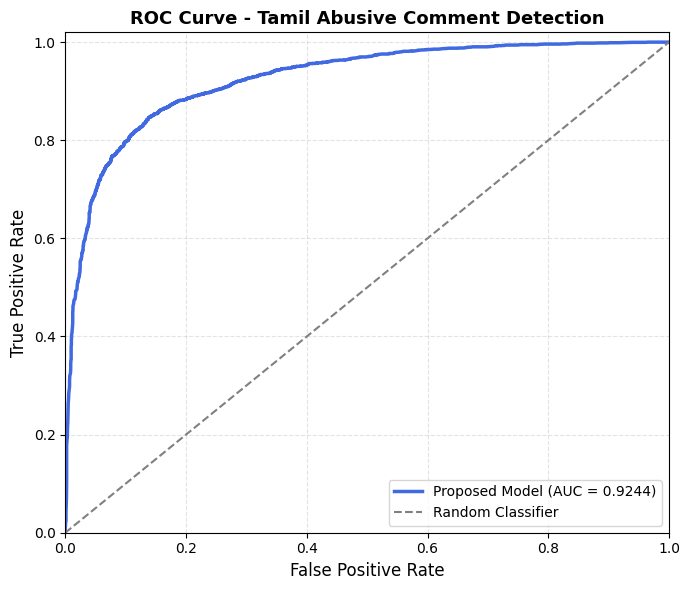

Validation ROC-AUC: 0.9244


In [22]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
auc_score = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr, tpr,
    color="royalblue",
    linewidth=2.5,
    label=f"Proposed Model (AUC = {auc_score:.4f})"
)
plt.plot(
    [0, 1], [0, 1],
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("ROC Curve - Tamil Abusive Comment Detection",
          fontsize=13, fontweight="bold")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.35)
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.tight_layout()

plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Validation ROC-AUC: {auc_score:.4f}")


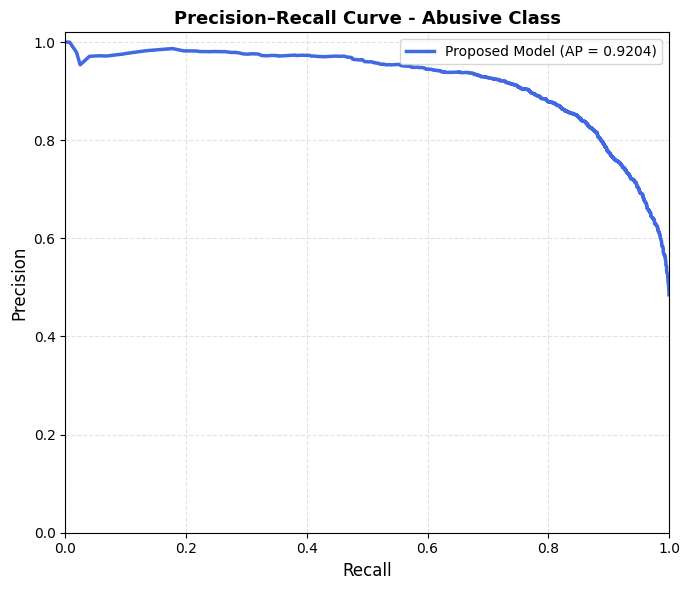

Validation Average Precision: 0.9204


In [23]:

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
avg_precision = average_precision_score(y_true, y_prob)

plt.figure(figsize=(7, 6))
plt.plot(
    recall, precision,
    color="royalblue",
    linewidth=2.5,
    label=f"Proposed Model (AP = {avg_precision:.4f})"
)

plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.title("Precision–Recall Curve - Abusive Class",
          fontsize=13, fontweight="bold")
plt.legend(loc="best")
plt.grid(True, linestyle="--", alpha=0.35)
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.tight_layout()

plt.savefig("precision_recall_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Validation Average Precision: {avg_precision:.4f}")


## 7. Training and validation

We select the best checkpoint by validation macro-F1 and stop early if it does not improve. Macro-F1 is reported because it treats both classes equally. The learning-rate scheduler is stepped after each optimizer update.

In [8]:
from sklearn.metrics import f1_score

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)
criterion = nn.CrossEntropyLoss()
use_amp = DEVICE.type == "cuda"
scaler_amp = torch.amp.GradScaler("cuda", enabled=use_amp)

def move_batch(batch):
    return {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}

@torch.no_grad()
def predict_loader(model, loader, with_labels=True):
    model.eval()
    all_probs, all_preds, all_labels, all_gates = [], [], [], []
    total_loss = 0.0
    total = 0
    for batch in loader:
        batch = move_batch(batch)
        labels = batch.get("labels")
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            logits, gates = model(
                batch["input_ids"], batch["attention_mask"],
                batch["char_ids"], batch["features"]
            )
            if labels is not None:
                loss = criterion(logits, labels)
                total_loss += loss.item() * labels.size(0)
                total += labels.size(0)
        probs = torch.softmax(logits.float(), dim=1)[:, 1]
        all_probs.extend(probs.cpu().numpy().tolist())
        all_preds.extend((probs >= 0.5).long().cpu().numpy().tolist())
        all_gates.extend(gates.float().cpu().numpy().tolist())
        if labels is not None:
            all_labels.extend(labels.cpu().numpy().tolist())
    output = {
        "probs": np.asarray(all_probs),
        "preds": np.asarray(all_preds),
        "gates": np.asarray(all_gates)
    }
    if with_labels and len(all_labels):
        output["labels"] = np.asarray(all_labels)
        output["loss"] = total_loss / max(total, 1)
    return output

best_f1 = -1
best_state = None
patience_left = PATIENCE
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, seen = 0.0, 0
    for batch in train_loader:
        batch = move_batch(batch)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            logits, _ = model(
                batch["input_ids"], batch["attention_mask"],
                batch["char_ids"], batch["features"]
            )
            loss = criterion(logits, batch["labels"])
        scaler_amp.scale(loss).backward()
        scaler_amp.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler_amp.step(optimizer)
        scaler_amp.update()
        scheduler.step()
        running_loss += loss.item() * batch["labels"].size(0)
        seen += batch["labels"].size(0)

    val_out = predict_loader(model, val_loader)
    val_acc = accuracy_score(val_out["labels"], val_out["preds"])
    val_p, val_r, val_f1, _ = precision_recall_fscore_support(
        val_out["labels"], val_out["preds"], average="macro", zero_division=0
    )
    row = {
        "epoch": epoch,
        "train_loss": running_loss / max(seen, 1),
        "val_loss": val_out["loss"],
        "val_accuracy": val_acc,
        "val_macro_precision": val_p,
        "val_macro_recall": val_r,
        "val_macro_f1": val_f1
    }
    history.append(row)
    print(row)

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
        torch.save(best_state, "/content/best_tamil_gated_fusion.pt")
        patience_left = PATIENCE
    else:
        patience_left -= 1
        if patience_left <= 0:
            print("Early stopping.")
            break

if best_state is None:
    raise RuntimeError("No model checkpoint was saved.")
model.load_state_dict(torch.load("/content/best_tamil_gated_fusion.pt", map_location=DEVICE))
pd.DataFrame(history)


{'epoch': 1, 'train_loss': 0.6112602676447473, 'val_loss': 0.4865366558808123, 'val_accuracy': 0.8021194605009634, 'val_macro_precision': 0.8051184584345037, 'val_macro_recall': 0.8004855423078174, 'val_macro_f1': 0.8008950241443449}
{'epoch': 2, 'train_loss': 0.4348831559036205, 'val_loss': 0.4151926029853968, 'val_accuracy': 0.8317919075144509, 'val_macro_precision': 0.8349139522683355, 'val_macro_recall': 0.8332454907080784, 'val_macro_f1': 0.8317004290146384}
{'epoch': 3, 'train_loss': 0.33865743649214947, 'val_loss': 0.4132148993038258, 'val_accuracy': 0.8414258188824663, 'val_macro_precision': 0.8438630048569346, 'val_macro_recall': 0.8427142122679138, 'val_macro_f1': 0.8413770532251423}
{'epoch': 4, 'train_loss': 0.2836524542872675, 'val_loss': 0.42684232095303104, 'val_accuracy': 0.8470134874759152, 'val_macro_precision': 0.8482083849426183, 'val_macro_recall': 0.8479417402738817, 'val_macro_f1': 0.847009034532953}


,epoch,train_loss,val_loss,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1
0,1,0.611260,0.486537,0.802119,0.805118,0.800486,0.800895
1,2,0.434883,0.415193,0.831792,0.834914,0.833245,0.831700
2,3,0.338657,0.413215,0.841426,0.843863,0.842714,0.841377
3,4,0.283652,0.426842,0.847013,0.848208,0.847942,0.847009


## 8. Validation metrics, confusion matrix, and ROC-AUC

These results are for the held-out validation split only. They should not be described as the final test score.

Validation accuracy: 0.847
Macro precision: 0.8482
Macro recall: 0.8479
Macro-F1: 0.847
ROC-AUC: 0.9226

Classification report:
                 precision    recall  f1-score   support

Non-abusive (0)     0.8775    0.8171    0.8462      2673
    Abusive (1)     0.8190    0.8788    0.8478      2517

       accuracy                         0.8470      5190
      macro avg     0.8482    0.8479    0.8470      5190
   weighted avg     0.8491    0.8470    0.8470      5190



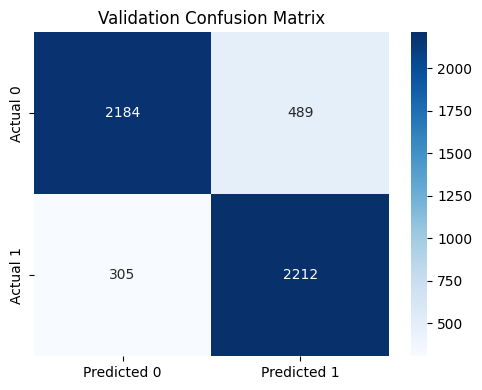

In [9]:
val_out = predict_loader(model, val_loader)
y_true = val_out["labels"]
y_pred = val_out["preds"]
y_prob = val_out["probs"]

print("Validation accuracy:", round(accuracy_score(y_true, y_pred), 4))
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
print("Macro precision:", round(p, 4))
print("Macro recall:", round(r, 4))
print("Macro-F1:", round(f1, 4))
try:
    print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 4))
except ValueError as e:
    print("ROC-AUC unavailable:", e)

print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=["Non-abusive (0)", "Abusive (1)"], digits=4, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"])
plt.title("Validation Confusion Matrix")
plt.tight_layout()
plt.show()


## 8B. Classical character TF-IDF baseline

Use this baseline alongside the neural model. It is particularly important for noisy spelling and transliterated text. All vocabulary is fitted on the training split only.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import FeatureUnion

char_word_features = FeatureUnion([
    ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=150000, sublinear_tf=True)),
    ("char", TfidfVectorizer(analyzer="char", ngram_range=(2, 5), min_df=2, max_features=250000, sublinear_tf=True))
])
Xtr_tfidf = char_word_features.fit_transform(train_texts)
Xva_tfidf = char_word_features.transform(val_texts)
svm_baseline = LinearSVC(class_weight="balanced", random_state=SEED)
svm_baseline.fit(Xtr_tfidf, y_train)
svm_pred = svm_baseline.predict(Xva_tfidf)

svm_p, svm_r, svm_f1, _ = precision_recall_fscore_support(y_val, svm_pred, average="macro", zero_division=0)
print("Word + character TF-IDF + LinearSVC")
print("Accuracy:", round(accuracy_score(y_val, svm_pred), 4))
print("Macro precision:", round(svm_p, 4))
print("Macro recall:", round(svm_r, 4))
print("Macro-F1:", round(svm_f1, 4))
print(classification_report(y_val, svm_pred, target_names=["Non-abusive (0)", "Abusive (1)"], digits=4, zero_division=0))


Word + character TF-IDF + LinearSVC
Accuracy: 0.8482
Macro precision: 0.848
Macro recall: 0.848
Macro-F1: 0.848
                 precision    recall  f1-score   support

Non-abusive (0)     0.8523    0.8530    0.8527      2673
    Abusive (1)     0.8437    0.8431    0.8434      2517

       accuracy                         0.8482      5190
      macro avg     0.8480    0.8480    0.8480      5190
   weighted avg     0.8482    0.8482    0.8482      5190



## 9. Inspect learned fusion weights

The gate values are model-dependent diagnostics. They are not, by themselves, proof that a branch is causally important. Compare them with ablation results.

MuRIL: mean gate weight = 0.9962
Character CNN: mean gate weight = 0.0025
Surface features: mean gate weight = 0.0013


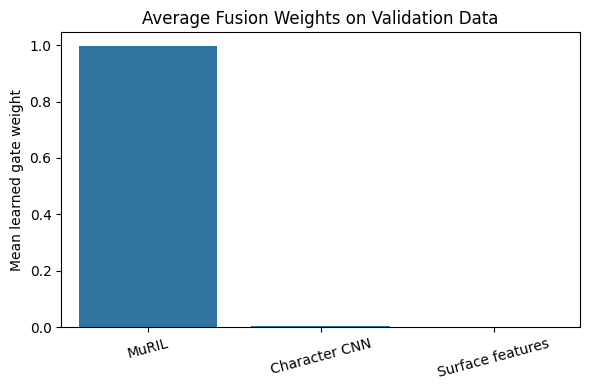

In [11]:
gate_names = ["MuRIL", "Character CNN", "Surface features"]
gate_means = val_out["gates"].mean(axis=0)
for name, value in zip(gate_names, gate_means):
    print(f"{name}: mean gate weight = {value:.4f}")

plt.figure(figsize=(6, 4))
sns.barplot(x=gate_names, y=gate_means)
plt.ylabel("Mean learned gate weight")
plt.title("Average Fusion Weights on Validation Data")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 10. Ablation study: MuRIL-only and MuRIL + surface features

Run this to test whether the extra branches help. Each variant is trained on the same train/validation split and uses the same evaluation procedure. Ablations require extra GPU time. If runtime is limited, run the full fusion model first, then run each ablation in a separate session.

In [12]:
def train_variant(use_char, use_features, run_epochs=3, patience=2):
    variant = GatedFusionClassifier(
        MODEL_NAME, CHAR_VOCAB_SIZE, X_train.shape[1],
        use_char=use_char, use_features=use_features
    ).to(DEVICE)
    opt = torch.optim.AdamW(variant.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    steps = len(train_loader) * run_epochs
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    amp_scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    best_score, best_weights, wait = -1, None, patience

    for ep in range(run_epochs):
        variant.train()
        for batch in train_loader:
            batch = move_batch(batch)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                logits, _ = variant(batch["input_ids"], batch["attention_mask"], batch["char_ids"], batch["features"])
                loss = criterion(logits, batch["labels"])
            amp_scaler.scale(loss).backward()
            amp_scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(variant.parameters(), 1.0)
            amp_scaler.step(opt)
            amp_scaler.update()
            sched.step()

        out = predict_loader(variant, val_loader)
        score = f1_score(out["labels"], out["preds"], average="macro", zero_division=0)
        print(f"epoch {ep+1}: validation macro-F1={score:.4f}")
        if score > best_score:
            best_score = score
            best_weights = copy.deepcopy({k: v.detach().cpu() for k, v in variant.state_dict().items()})
            wait = patience
        else:
            wait -= 1
            if wait <= 0:
                break

    variant.load_state_dict(best_weights)
    out = predict_loader(variant, val_loader)
    p, r, f, _ = precision_recall_fscore_support(out["labels"], out["preds"], average="macro", zero_division=0)
    return variant, {
        "use_char": use_char, "use_features": use_features,
        "accuracy": accuracy_score(out["labels"], out["preds"]),
        "macro_precision": p, "macro_recall": r, "macro_f1": f
    }

# Main full model results are already available as `val_out`.
ablation_results = [{
    "model": "MuRIL + Character CNN + Features",
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)[0],
    "macro_recall": precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)[1],
    "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)
}]

# Uncomment one or both lines to train ablations (additional GPU time):
# muril_only_model, muril_only_metrics = train_variant(use_char=False, use_features=False)
# ablation_results.append({"model": "MuRIL only", **{k:v for k,v in muril_only_metrics.items() if k not in ["use_char","use_features"]}})

# muril_surface_model, muril_surface_metrics = train_variant(use_char=False, use_features=True)
# ablation_results.append({"model": "MuRIL + Surface Features", **{k:v for k,v in muril_surface_metrics.items() if k not in ["use_char","use_features"]}})

pd.DataFrame(ablation_results)


,model,accuracy,macro_precision,macro_recall,macro_f1
0,MuRIL + Character CNN + Features,0.847013,0.848208,0.847942,0.847009


In [15]:

# Store the results of all four experiments
ablation_results = []

# EXPERIMENT 1: Full proposed model
# MuRIL + Character CNN + Surface Features
ablation_results.append({
    "model": "Full Fusion (MuRIL + CNN + Features)",
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )[0],
    "macro_recall": precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )[1],
    "macro_f1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )
})

# EXPERIMENT 2: MuRIL only
muril_only_model, muril_only_metrics = train_variant(
    use_char=False,
    use_features=False,
    run_epochs=3,
    patience=2
)

ablation_results.append({
    "model": "MuRIL Only",
    "accuracy": muril_only_metrics["accuracy"],
    "macro_precision": muril_only_metrics["macro_precision"],
    "macro_recall": muril_only_metrics["macro_recall"],
    "macro_f1": muril_only_metrics["macro_f1"]
})

# EXPERIMENT 3: MuRIL + Surface Features
muril_surface_model, muril_surface_metrics = train_variant(
    use_char=False,
    use_features=True,
    run_epochs=3,
    patience=2
)

ablation_results.append({
    "model": "MuRIL + Surface Features",
    "accuracy": muril_surface_metrics["accuracy"],
    "macro_precision": muril_surface_metrics["macro_precision"],
    "macro_recall": muril_surface_metrics["macro_recall"],
    "macro_f1": muril_surface_metrics["macro_f1"]
})

# EXPERIMENT 4: MuRIL + Character CNN
muril_char_model, muril_char_metrics = train_variant(
    use_char=True,
    use_features=False,
    run_epochs=3,
    patience=2
)

ablation_results.append({
    "model": "MuRIL + Character CNN",
    "accuracy": muril_char_metrics["accuracy"],
    "macro_precision": muril_char_metrics["macro_precision"],
    "macro_recall": muril_char_metrics["macro_recall"],
    "macro_f1": muril_char_metrics["macro_f1"]
})

# Display the comparison table
ablation_df = pd.DataFrame(ablation_results)
ablation_df = ablation_df.sort_values(
    by="macro_f1", ascending=False
).reset_index(drop=True)

display(ablation_df.round(4))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: validation macro-F1=0.7674
epoch 2: validation macro-F1=0.8060
epoch 3: validation macro-F1=0.8328


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: validation macro-F1=0.7974
epoch 2: validation macro-F1=0.8357
epoch 3: validation macro-F1=0.8366


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1: validation macro-F1=0.8110
epoch 2: validation macro-F1=0.8474
epoch 3: validation macro-F1=0.8472


,model,accuracy,macro_precision,macro_recall,macro_f1
0,MuRIL + Character CNN,0.8478,0.8485,0.8470,0.8474
1,Full Fusion (MuRIL + CNN + Features),0.8470,0.8482,0.8479,0.8470
2,MuRIL + Surface Features,0.8366,0.8378,0.8375,0.8366
3,MuRIL Only,0.8329,0.8328,0.8327,0.8328


In [16]:

import unicodedata
import pandas as pd

def normalize_for_duplicate_check(text):
    text = unicodedata.normalize("NFKC", str(text))
    text = " ".join(text.split())
    return text.casefold()

# Check duplicates in the complete labeled dataset
duplicate_check = train_df.copy()
duplicate_check["normalized_text"] = (
    duplicate_check["Text"].map(normalize_for_duplicate_check)
)

print("Total training rows:", len(duplicate_check))
print(
    "Repeated normalized texts:",
    int(duplicate_check["normalized_text"].duplicated().sum())
)

# Check whether identical normalized texts have conflicting labels
label_counts = duplicate_check.groupby("normalized_text")["Class"].nunique()

print(
    "Duplicate text groups with conflicting labels:",
    int((label_counts > 1).sum())
)

# Check overlap between the current training and validation splits
train_norm = {
    normalize_for_duplicate_check(t) for t in train_texts
}
val_norm = {
    normalize_for_duplicate_check(t) for t in val_texts
}

overlap = train_norm & val_norm

print(
    "Normalized texts shared across train/validation:",
    len(overlap)
)


Total training rows: 25946
Repeated normalized texts: 58
Duplicate text groups with conflicting labels: 1
Normalized texts shared across train/validation: 14


In [17]:

# Inspect duplicate groups with conflicting labels
conflicting_texts = label_counts[label_counts > 1].index.tolist()

print("=== CONFLICTING LABEL GROUPS ===")

for text in conflicting_texts:
    rows = duplicate_check[
        duplicate_check["normalized_text"] == text
    ][["Text", "Class"]]

    print("\nNormalized text:", repr(text))
    display(rows)

# Inspect comments shared across training and validation
print("\n=== TRAIN/VALIDATION OVERLAP ===")

overlap_rows = duplicate_check[
    duplicate_check["normalized_text"].isin(overlap)
][["Text", "Class", "normalized_text"]]

display(overlap_rows.sort_values("normalized_text"))


=== CONFLICTING LABEL GROUPS ===

Normalized text: 'ரெண்டு பேரையும் செருப்புலே அடிச்சு தொரத்தரதை தவிர வேறு வழி இல்லை'


,Text,Class
2580,ரெண்டு பேரையும் செருப்புலே அடிச்சு தொரத்தரதை த...,0
16025,ரெண்டு பேரையும் செருப்புலே அடிச்சு தொரத்தரதை த...,1



=== TRAIN/VALIDATION OVERLAP ===


,Text,Class,normalized_text
884,அந்த பொண்ணுக்கு பேய் கூட பயமா இருக்கு மேடம்,1,அந்த பொண்ணுக்கு பேய் கூட பயமா இருக்கு மேடம்
1233,அந்த பொண்ணுக்கு பேய் கூட பயமா இருக்கு மேடம்,1,அந்த பொண்ணுக்கு பேய் கூட பயமா இருக்கு மேடம்
3516,இது ஒரு மூஞ்சிக் புண்ட இவளுக்கு பவுன் போடணுமா ...,1,இது ஒரு மூஞ்சிக் புண்ட இவளுக்கு பவுன் போடணுமா ...
24928,இது ஒரு மூஞ்சிக் புண்ட இவளுக்கு பவுன் போடணுமா ...,1,இது ஒரு மூஞ்சிக் புண்ட இவளுக்கு பவுன் போடணுமா ...
14518,என்ன செய்தாலும் தேவிடியா பைத்தியம்,1,என்ன செய்தாலும் தேவிடியா பைத்தியம்
22736,என்ன செய்தாலும் தேவிடியா பைத்தியம்,1,என்ன செய்தாலும் தேவிடியா பைத்தியம்
19495,ஒரு நாள் என் வாழ்க்கையில் வீடியோ போடுங்க,0,ஒரு நாள் என் வாழ்க்கையில் வீடியோ போடுங்க
16520,ஒரு நாள் என் வாழ்க்கையில் வீடியோ போடுங்க,0,ஒரு நாள் என் வாழ்க்கையில் வீடியோ போடுங்க
21675,கடஞ்சி எடுத்து பைத்தியம் எல்லாரும் அன்சப்ஸ்கிர...,1,கடஞ்சி எடுத்து பைத்தியம் எல்லாரும் அன்சப்ஸ்கிர...
19320,கடஞ்சி எடுத்து பைத்தியம் எல்லாரும் அன்சப்ஸ்கிர...,1,கடஞ்சி எடுத்து பைத்தியம் எல்லாரும் அன்சப்ஸ்கிர...


In [18]:

import unicodedata
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

def normalize_for_duplicate_check(text):
    text = unicodedata.normalize("NFKC", str(text))
    return " ".join(text.split()).casefold()

# Work on a copy; preserve the original train_df
clean_df = train_df.copy()
clean_df["normalized_text"] = (
    clean_df["Text"].astype(str).map(normalize_for_duplicate_check)
)

# Identify normalized text groups with conflicting labels
label_counts = clean_df.groupby("normalized_text")["Class"].nunique()
conflicting_groups = label_counts[label_counts > 1].index

print("Conflicting text groups excluded:", len(conflicting_groups))

# Exclude the entire ambiguous group, not just one of its labels
clean_df = clean_df[
    ~clean_df["normalized_text"].isin(conflicting_groups)
].reset_index(drop=True)

# Split by normalized-text group so duplicates cannot cross splits
X = clean_df["Text"].astype(str)
y = clean_df["Class"].astype(int)
groups = clean_df["normalized_text"]

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

train_texts = X.iloc[train_idx].tolist()
val_texts = X.iloc[val_idx].tolist()

train_labels = y.iloc[train_idx].to_numpy()
val_labels = y.iloc[val_idx].to_numpy()

print("Training rows:", len(train_idx))
print("Validation rows:", len(val_idx))
print("Training label distribution:")
print(pd.Series(train_labels).value_counts().sort_index())
print("Validation label distribution:")
print(pd.Series(val_labels).value_counts().sort_index())

train_groups = set(groups.iloc[train_idx])
val_groups = set(groups.iloc[val_idx])

print("Shared normalized text groups:", len(train_groups & val_groups))


Conflicting text groups excluded: 1
Training rows: 20751
Validation rows: 5193
Training label distribution:
0    10682
1    10069
Name: count, dtype: int64
Validation label distribution:
0    2678
1    2515
Name: count, dtype: int64
Shared normalized text groups: 0


In [19]:

# Use the corrected grouped split already created
y_train = np.asarray(train_labels, dtype=np.int64)
y_val = np.asarray(val_labels, dtype=np.int64)

assert len(train_texts) == len(y_train)
assert len(val_texts) == len(y_val)

assert len({
    normalize_for_duplicate_check(t) for t in train_texts
} & {
    normalize_for_duplicate_check(t) for t in val_texts
}) == 0

print("Corrected split verified.")
print("Train:", len(train_texts), "| Validation:", len(val_texts))
print("Train labels:", np.bincount(y_train))
print("Validation labels:", np.bincount(y_val))


Corrected split verified.
Train: 20751 | Validation: 5193
Train labels: [10682 10069]
Validation labels: [2678 2515]


In [22]:
import gc
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

print(torch.cuda.get_device_name(0))
print(f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print(f"Reserved:  {torch.cuda.memory_reserved() / 1024**3:.2f} GB")

Tesla T4
Allocated: 10.72 GB
Reserved:  12.52 GB


In [1]:
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print("GPU:", torch.cuda.get_device_name(0))
print(f"Allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
print(f"Reserved:  {torch.cuda.memory_reserved() / 1024**3:.2f} GB")

GPU: Tesla T4
Allocated: 0.00 GB
Reserved:  0.00 GB


In [2]:
import torch
from transformers import AutoModel

BATCH_SIZE = 4
MAX_LEN = 96
GRAD_ACCUM_STEPS = 4

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [3]:

import copy
import math
import gc
import torch
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)

GRAD_ACCUM_STEPS = 4

def train_variant(use_char, use_features, run_epochs=3, patience=2):
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    variant = GatedFusionClassifier(
        MODEL_NAME,
        CHAR_VOCAB_SIZE,
        X_train.shape[1],
        use_char=use_char,
        use_features=use_features
    ).to(DEVICE)

    # Gradient checkpointing reduces MuRIL activation memory.
    # If your classifier's MuRIL backbone is named differently,
    # enable checkpointing on that backbone inside GatedFusionClassifier.
    if hasattr(variant, "muril"):
        variant.muril.gradient_checkpointing_enable()

    opt = torch.optim.AdamW(
        variant.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    updates_per_epoch = math.ceil(
        len(train_loader) / GRAD_ACCUM_STEPS
    )
    total_steps = updates_per_epoch * run_epochs
    sched = get_linear_schedule_with_warmup(
        opt,
        int(0.1 * total_steps),
        total_steps
    )

    amp_scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(DEVICE.type == "cuda" and use_amp)
    )

    best_score = -1.0
    best_weights = None
    wait = patience

    for ep in range(run_epochs):
        variant.train()
        opt.zero_grad(set_to_none=True)

        for step, batch in enumerate(train_loader):
            batch = move_batch(batch)

            # Correctly handle the final incomplete accumulation group.
            group_start = (step // GRAD_ACCUM_STEPS) * GRAD_ACCUM_STEPS
            group_size = min(
                GRAD_ACCUM_STEPS,
                len(train_loader) - group_start
            )

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda" and use_amp)
            ):
                logits, _ = variant(
                    batch["input_ids"],
                    batch["attention_mask"],
                    batch["char_ids"],
                    batch["features"]
                )
                loss = criterion(logits, batch["labels"])
                loss = loss / group_size

            amp_scaler.scale(loss).backward()

            update_now = (
                (step + 1) % GRAD_ACCUM_STEPS == 0
                or (step + 1) == len(train_loader)
            )

            if update_now:
                amp_scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(
                    variant.parameters(), 1.0
                )
                amp_scaler.step(opt)
                amp_scaler.update()
                opt.zero_grad(set_to_none=True)
                sched.step()

        out = predict_loader(variant, val_loader)
        score = f1_score(
            out["labels"], out["preds"],
            average="macro", zero_division=0
        )
        print(f"Epoch {ep+1}: validation macro-F1 = {score:.4f}")

        if score > best_score:
            best_score = score
            best_weights = {
                k: v.detach().cpu().clone()
                for k, v in variant.state_dict().items()
            }
            wait = patience
        else:
            wait -= 1
            if wait <= 0:
                break

    if best_weights is None:
        raise RuntimeError("No valid checkpoint was saved.")

    variant.load_state_dict(best_weights)
    out = predict_loader(variant, val_loader)

    p, r, f, _ = precision_recall_fscore_support(
        out["labels"], out["preds"],
        average="macro", zero_division=0
    )

    metrics = {
        "use_char": use_char,
        "use_features": use_features,
        "accuracy": accuracy_score(out["labels"], out["preds"]),
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f
    }

    return variant, metrics


In [5]:

# Memory-efficient DataLoader setup for the Tesla T4
import gc
import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 4
MAX_LENGTH = 96
MAX_CHARS = 300

# Check that the split and preprocessing variables exist.
required = [
    "train_texts", "val_texts", "test_texts",
    "y_train", "y_val", "X_train", "X_val", "X_test",
    "tokenizer", "TamilAbuseDataset", "encode_chars"
]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Run the data-loading, corrected grouped-split, and feature "
        f"preprocessing cells first. Missing: {missing}"
    )

# Recreate datasets using the current MAX_LENGTH.
train_ds = TamilAbuseDataset(train_texts, X_train, y_train)
val_ds = TamilAbuseDataset(val_texts, X_val, y_val)
test_ds = TamilAbuseDataset(test_texts, X_test, labels=None)

# num_workers=0 is a safer choice for debugging in Colab.
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_ds,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

print("Training rows:", len(train_ds))
print("Validation rows:", len(val_ds))
print("Unlabeled test rows:", len(test_ds))
print("Training batch size:", train_loader.batch_size)
print("Validation batch size:", val_loader.batch_size)
print("GPU:", torch.cuda.get_device_name(0))


RuntimeError: Run the data-loading, corrected grouped-split, and feature preprocessing cells first. Missing: ['train_texts', 'val_texts', 'test_texts', 'y_train', 'y_val', 'X_train', 'X_val', 'X_test', 'tokenizer', 'TamilAbuseDataset', 'encode_chars']

In [23]:
ablation_results = []

print("Training MuRIL only...")
_, metrics = train_variant(False, False, run_epochs=3, patience=2)
ablation_results.append({
    "model": "MuRIL Only",
    **metrics
})

gc.collect()
torch.cuda.empty_cache()

Training MuRIL only...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


OutOfMemoryError: CUDA out of memory. Tried to allocate 578.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 213.81 MiB is free. Including non-PyTorch memory, this process has 14.35 GiB memory in use. Of the allocated memory 13.09 GiB is allocated by PyTorch, and 1.13 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [21]:

# The full fusion model must have been retrained on the corrected split.
# The latest val_out, y_true and y_pred should come from that run.

ablation_results = []

# Full fusion model: newly retrained result
p, r, _, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)
ablation_results.append({
    "model": "Full Fusion (MuRIL + CNN + Features)",
    "accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": p,
    "macro_recall": r,
    "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)
})

# MuRIL only
print("\nTraining MuRIL only...")
_, m = train_variant(False, False, run_epochs=3, patience=2)
ablation_results.append({
    "model": "MuRIL Only",
    "accuracy": m["accuracy"],
    "macro_precision": m["macro_precision"],
    "macro_recall": m["macro_recall"],
    "macro_f1": m["macro_f1"]
})

# MuRIL + surface features
print("\nTraining MuRIL + Surface Features...")
_, m = train_variant(False, True, run_epochs=3, patience=2)
ablation_results.append({
    "model": "MuRIL + Surface Features",
    "accuracy": m["accuracy"],
    "macro_precision": m["macro_precision"],
    "macro_recall": m["macro_recall"],
    "macro_f1": m["macro_f1"]
})

# MuRIL + character CNN
print("\nTraining MuRIL + Character CNN...")
_, m = train_variant(True, False, run_epochs=3, patience=2)
ablation_results.append({
    "model": "MuRIL + Character CNN",
    "accuracy": m["accuracy"],
    "macro_precision": m["macro_precision"],
    "macro_recall": m["macro_recall"],
    "macro_f1": m["macro_f1"]
})

ablation_df = pd.DataFrame(ablation_results).sort_values(
    "macro_f1", ascending=False
).reset_index(drop=True)

display(ablation_df.round(4))
ablation_df.to_csv(
    "/content/corrected_ablation_results.csv", index=False
)
print("Saved /content/corrected_ablation_results.csv")



Training MuRIL only...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google/muril-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


OutOfMemoryError: CUDA out of memory. Tried to allocate 578.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 213.81 MiB is free. Including non-PyTorch memory, this process has 14.35 GiB memory in use. Of the allocated memory 13.09 GiB is allocated by PyTorch, and 1.13 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

## 11. Predict the 913 unlabeled test comments and save files

The prediction CSV includes the predicted class and probability of class 1. Since the test file has no labels, do not report accuracy, F1, or ROC-AUC for it. Verify the predicted class distribution and inspect a sample of predictions before any submission.

In [13]:
test_out = predict_loader(model, test_loader, with_labels=False)
test_predictions = test_df.copy()
test_predictions["Predicted_Class"] = test_out["preds"]
test_predictions["Probability_Abusive"] = test_out["probs"]

print("Predicted class distribution:")
print(test_predictions["Predicted_Class"].value_counts().sort_index())
print("\nSample predictions:")
display(test_predictions.head(10))

pred_path = "/content/tamil_abusive_comment_predictions.csv"
test_predictions.to_csv(pred_path, index=False)
print("Saved:", pred_path)

from google.colab import files
files.download(pred_path)


Predicted class distribution:
Predicted_Class
0    545
1    368
Name: count, dtype: int64

Sample predictions:


,Text,Predicted_Class,Probability_Abusive
0,லக்ஷ்மி அம்மா நீங்க புலம்புங்க அவளுக அவளுகபாட்...,1,0.534210
1,"இன்னும் கைது பண்ணல... அனைத்து பெற்றோர்களும், க...",0,0.335514
2,"அப்பா,அம்மா, அந்த இன்டர்வியூ பண்ற வக்கிரம்புடி...",1,0.817210
3,Suganthi உனக்கு வீட்ல குழந்தையை வச்சிருக்க கார...,0,0.125012
4,எல்லாமே script thaan. ஷகீலா உங்க scriptum அரும...,0,0.055875
5,எங்க ரூம்லயும் ஒரு கார்த்தி இருக்கான்..... அவன...,0,0.063540
6,பச்ச தேவடியாலுக்கும் ....விசத்தேவடியாலுக்கும் ...,1,0.970352
7,ஆளானப்பட்ட லட்சுமி மேடத்தயே தனியா பேச வச்சிட்ட...,0,0.057705
8,து து து நீ எல்லாம் ஒரு பொண்ணு. சனியனே எப்படி ...,1,0.963882
9,நாட்டுக்கு ரொம்ப முக்கியம் இது.... மக்கள கெடு...,0,0.063424


Saved: /content/tamil_abusive_comment_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Save the model artifacts for reproducibility

Save the tokenizer, character vocabulary, scaler, and model weights together. Keep these files private until you have checked dataset and competition rules. A model checkpoint alone is not enough to reproduce predictions because this model also depends on preprocessing and feature-scaling artifacts.

In [14]:
import pickle, json, shutil, os

ARTIFACT_DIR = "/content/tamil_abuse_model_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)
shutil.copy("/content/best_tamil_gated_fusion.pt", os.path.join(ARTIFACT_DIR, "best_tamil_gated_fusion.pt"))
tokenizer.save_pretrained(ARTIFACT_DIR)
with open(os.path.join(ARTIFACT_DIR, "char_to_id.json"), "w", encoding="utf-8") as f:
    json.dump(char_to_id, f, ensure_ascii=False)
with open(os.path.join(ARTIFACT_DIR, "feature_scaler.pkl"), "wb") as f:
    pickle.dump(scaler, f)
with open(os.path.join(ARTIFACT_DIR, "feature_names.json"), "w", encoding="utf-8") as f:
    json.dump(FEATURE_NAMES, f, ensure_ascii=False, indent=2)
with open(os.path.join(ARTIFACT_DIR, "run_config.json"), "w", encoding="utf-8") as f:
    json.dump({
        "model_name": MODEL_NAME, "max_length": MAX_LENGTH,
        "max_chars": MAX_CHARS, "seed": SEED,
        "labels": {"0": "non-abusive", "1": "abusive"},
        "architecture": "MuRIL + multi-kernel Character CNN + surface features + learned gated fusion"
    }, f, indent=2)

artifact_zip = shutil.make_archive("/content/tamil_abuse_model_artifacts", "zip", ARTIFACT_DIR)
print("Saved artifacts:", artifact_zip)
files.download(artifact_zip)


Saved artifacts: /content/tamil_abuse_model_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. What to report in the paper

Report the validation metrics from this notebook honestly and label them as validation results. Before making a novelty claim:

1. Compare the full model with MuRIL-only, MuRIL + surface features, and character TF-IDF + SVM.
2. Repeat important experiments across multiple random seeds and report mean ± standard deviation.
3. Confirm that label mapping is correct (`0 = non-abusive`, `1 = abusive`) using the dataset documentation.
4. Keep the unlabeled test predictions separate from labelled evaluation.
5. Compare with recent papers on the same task and follow the target conference's dataset, citation, and reproducibility requirements.
6. Do not claim the proposed model is superior unless the measured experiments support that conclusion.
